EDA

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Adjust the visualization style
plt.style.use('ggplot')

# Load the dataset
# REPLACE 'your_dataset.csv' with your actual file name
try:
    df = pd.read_csv('Question Answer Classification Dataset 4.csv')
    print("Data loaded successfully!")
except FileNotFoundError:
    print("File not found. Please check the file name/path.")

# Display the first few rows and general info
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Data Info ---")
df.info()

Data loaded successfully!

--- First 5 Rows ---


,QA Text,Class
0,<html> Question Title:\n <br> What are the nam...,Science & Mathematics
1,<html> Question Title:\n <br> can you tell me ...,Education & Reference
2,<html> Question Title:\n <br> Suggestions or A...,Politics & Government
3,<html> Question Title:\n <br> where can i find...,Entertainment & Music
4,<html> Question Title:\n <br> will the first t...,Sports



--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93333 entries, 0 to 93332
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   QA Text  93333 non-null  object
 1   Class    93333 non-null  object
dtypes: object(2)
memory usage: 1.4+ MB


Preprocess


In [4]:
!pip install nltk

In [5]:
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize


nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tamal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tamal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [6]:
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from bs4 import BeautifulSoup
import re

# 1. Download NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

# 2. Load the CSV
# Replace with your actual path from Google Drive
file_path = 'D:\BRACu\CSE440\Project440\Question Answer Classification Dataset 4.csv'
df = pd.read_csv(file_path)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tamal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tamal\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\tamal\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\tamal\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tamal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [7]:
# 3. Define the Cleaning Function
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_and_process(text):
    # A. Remove HTML tags
    text = str(text)
    text = text.replace("Question Title:", "")
    text = text.replace("Question Content:", "")
    text = text.replace("Best Answer:", "")
    soup = BeautifulSoup(text, "html.parser")
    clean_text = soup.get_text(separator=" ")

    # B. Tokenize
    tokens = word_tokenize(clean_text)

    # C. Remove Stopwords & Lemmatize
    processed_tokens = []
    for token in tokens:
        token_lower = token.lower()
        if token_lower not in stop_words and token.isalnum():
            lemma = lemmatizer.lemmatize(token_lower)
            processed_tokens.append(lemma)

    # D. Return as a single string (needed for Keras/Deep Learning later)
    return " ".join(processed_tokens)

# 4. Apply to 'QA Text' (NOT Class!)
df['Cleaned_Text'] = df['QA Text'].apply(clean_and_process)

print(df[['QA Text', 'Cleaned_Text', 'Class']].head())

                                             QA Text  \
0  <html> Question Title:\n <br> What are the nam...   
1  <html> Question Title:\n <br> can you tell me ...   
2  <html> Question Title:\n <br> Suggestions or A...   
3  <html> Question Title:\n <br> where can i find...   
4  <html> Question Title:\n <br> will the first t...   

                                        Cleaned_Text                  Class  
0  name 206 bone human body 206 bone human body a...  Science & Mathematics  
1  tell university name distance mphil food nutri...  Education & Reference  
2  suggestion advice tracking someone owes money ...  Politics & Government  
3  find system poem victim written guitarist band...  Entertainment & Music  
4  first tour match india south africa telecast c...                 Sports  


C:\Users\tamal\AppData\Local\Temp\ipykernel_18752\1567138508.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.values, y=class_counts.index, palette='viridis')


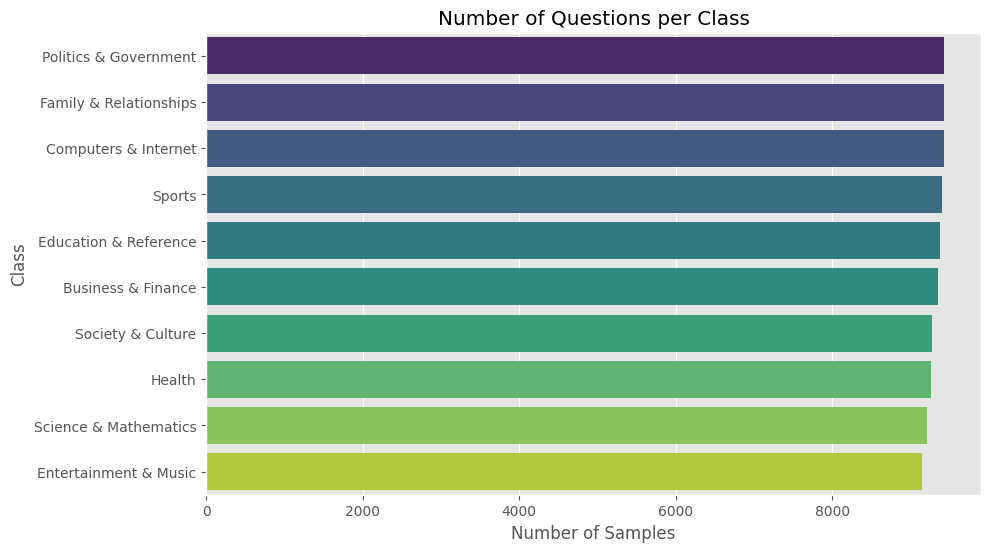

Class
Politics & Government     9432
Family & Relationships    9432
Computers & Internet      9429
Sports                    9404
Education & Reference     9385
Business & Finance        9350
Society & Culture         9271
Health                    9263
Science & Mathematics     9217
Entertainment & Music     9150
Name: count, dtype: int64


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate counts
class_counts = df['Class'].value_counts()

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.values, y=class_counts.index, palette='viridis')
plt.title('Number of Questions per Class')
plt.xlabel('Number of Samples')
plt.ylabel('Class')
plt.show()

# Print exact numbers
print(class_counts)

LABEL ENCODING

In [9]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import numpy as np

# 1. Encode the Labels (Class -> Numbers)
le = LabelEncoder()
df['Class_Label'] = le.fit_transform(df['Class'])

# Show which number represents which topic
print("--- Class Mapping ---")
for i, label in enumerate(le.classes_):
    print(f"{i}: {label}")

# 2. Split into Train and Test sets
# We use 'Cleaned_Text' as input (X) and 'Class_Label' as output (y)
X = df['Cleaned_Text'].values
y = df['Class_Label'].values

# Split: 80% for training, 20% for testing
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"--- Internal Split ---")
print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")

--- Class Mapping ---
0: Business & Finance
1: Computers & Internet
2: Education & Reference
3: Entertainment & Music
4: Family & Relationships
5: Health
6: Politics & Government
7: Science & Mathematics
8: Society & Culture
9: Sports
--- Internal Split ---
Training samples: 74666
Validation samples: 18667


Tokenize

In [24]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

# 1. Setup Parameters
VOCAB_SIZE = 20000     
OOV_TOK = "<OOV>"      

# 2. Train the Tokenizer
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOK)
tokenizer.fit_on_texts(X_train)

# 3. Convert Text to Numbers
train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)

# 4. Dynamic Max Length Calculation
lengths = [len(x) for x in train_sequences]
MAX_LENGTH = 200
print(f"Stats:")

# 5. Pad the Sequences
X_train_padded = pad_sequences(train_sequences, maxlen=MAX_LENGTH, padding='post', truncating='post')
X_val_padded = pad_sequences(val_sequences, maxlen=MAX_LENGTH, padding='post', truncating='post')

print(f"New Data Shape: {X_train_padded.shape}")
print(f"Validation Data Shape: {X_val_padded.shape}")

Stats:
New Data Shape: (74666, 200)
Validation Data Shape: (18667, 200)


TF-IDF

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Setup TF-IDF
# We limit to 5000 features to keep the input size manageable for the Dense Network
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

# 2. Fit and Transform
# Note: We use the text strings (Cleaned_Text), NOT the sequences
X_train_tfidf = tfidf.fit_transform(X_train).toarray()
X_val_tfidf = tfidf.transform(X_val).toarray()

print(f"TF-IDF Train Shape: {X_train_tfidf.shape}")
print(f"TF-IDF Val Shape: {X_val_tfidf.shape}")

TF-IDF Train Shape: (74666, 5000)
TF-IDF Val Shape: (18667, 5000)


DNN

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Define the DNN Model
model_dnn = Sequential([
    Dense(512, input_dim=5000, activation='relu'),
    Dropout(0.5), # Helps prevent overfitting
    
    # Hidden Layer
    Dense(256, activation='relu'),
    Dropout(0.5),
    
    # Output Layer (10 Classes)
    Dense(10, activation='softmax')
])

model_dnn.compile(loss='sparse_categorical_crossentropy', 
                  optimizer='adam', 
                  metrics=['accuracy'])

model_dnn.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_12 (Dense)            (None, 512)               2560512   
                                                                 
 dropout_8 (Dropout)         (None, 512)               0         
                                                                 
 dense_13 (Dense)            (None, 256)               131328    
                                                                 
 dropout_9 (Dropout)         (None, 256)               0         
                                                                 
 dense_14 (Dense)            (None, 10)                2570      
                                                                 
Total params: 2,694,410
Trainable params: 2,694,410
Non-trainable params: 0
_________________________________________________________________


In [30]:
# Train the model
history_dnn = model_dnn.fit(
    X_train_tfidf, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_tfidf, y_val),
    verbose=1
)

Epoch 1/10
2334/2334 [==============================] - 9s 4ms/step - loss: 1.1985 - accuracy: 0.6220 - val_loss: 1.0450 - val_accuracy: 0.6686
Epoch 2/10
2334/2334 [==============================] - 9s 4ms/step - loss: 0.9301 - accuracy: 0.7047 - val_loss: 1.0519 - val_accuracy: 0.6666
Epoch 3/10
2334/2334 [==============================] - 10s 4ms/step - loss: 0.7822 - accuracy: 0.7469 - val_loss: 1.1196 - val_accuracy: 0.6601
Epoch 4/10
2334/2334 [==============================] - 9s 4ms/step - loss: 0.6313 - accuracy: 0.7968 - val_loss: 1.1917 - val_accuracy: 0.6552
Epoch 5/10
2334/2334 [==============================] - 9s 4ms/step - loss: 0.4778 - accuracy: 0.8464 - val_loss: 1.3100 - val_accuracy: 0.6480
Epoch 6/10
2334/2334 [==============================] - 9s 4ms/step - loss: 0.3608 - accuracy: 0.8821 - val_loss: 1.4886 - val_accuracy: 0.6424
Epoch 7/10
2334/2334 [==============================] - 9s 4ms/step - loss: 0.2736 - accuracy: 0.9108 - val_loss: 1.6704 - val_accuracy

In [31]:
from sklearn.metrics import classification_report
import numpy as np

def print_report(model, X_data, y_true, model_name="Model"):
    # 1. Predict (returns probabilities for each of the 10 classes)
    y_pred_probs = model.predict(X_data)
    
    # 2. Convert Probabilities to Class Labels (Pick the highest probability)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)
    
    # 3. Get the Class Names (Optional: makes the report readable)
    # We use the LabelEncoder 'le' from Step 4
    class_names = [str(c) for c in le.classes_]
    
    print(f"\n--- Classification Report: {model_name} ---")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

# --- Example Usage for your Tuned DNN ---
# Make sure to use the correct X data (TF-IDF for DNN, Padded for GRU)
print_report(model_dnn, X_val_tfidf, y_val, "DNN:")

584/584 [==============================] - 1s 1ms/step

--- Classification Report: DNN: ---
                        precision    recall  f1-score   support

    Business & Finance       0.51      0.43      0.47      1930
  Computers & Internet       0.80      0.81      0.80      1926
 Education & Reference       0.47      0.45      0.46      1828
 Entertainment & Music       0.57      0.63      0.60      1771
Family & Relationships       0.67      0.71      0.69      1917
                Health       0.74      0.72      0.73      1838
 Politics & Government       0.67      0.73      0.70      1885
 Science & Mathematics       0.62      0.67      0.64      1779
     Society & Culture       0.57      0.51      0.54      1921
                Sports       0.79      0.77      0.78      1872

              accuracy                           0.64     18667
             macro avg       0.64      0.64      0.64     18667
          weighted avg       0.64      0.64      0.64     18667



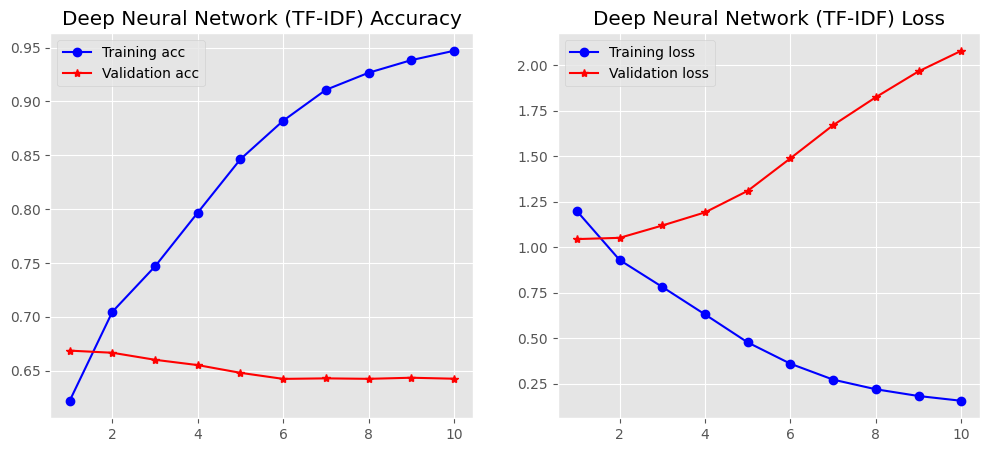

In [32]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training acc')
    plt.plot(epochs, val_acc, 'r*-', label='Validation acc')
    plt.title(f'{model_name} Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation loss')
    plt.title(f'{model_name} Loss')
    plt.legend()

    plt.show()

# Plot the DNN results
plot_history(history_dnn, "Deep Neural Network (TF-IDF)")

DNN-TUNED

In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# --- HYPERPARAMETER TUNING SETUP ---

# 1. Define Callbacks (The "Smart" stopping logic)
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=3,             # Stop if val_loss gets worse for 3 epochs in a row
    restore_best_weights=True # Go back to the best version of the model, not the last one
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2,             # Reduce learning rate by 80% if stuck
    patience=1, 
    min_lr=0.0001
)

# 2. Build Tuned Model (Added L2 Regularization)
model_dnn_tuned = Sequential([
    # Added kernel_regularizer=l2(0.001) to punish memorization
    Dense(64, input_dim=5000, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.4),
    
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.6),
    
    Dense(10, activation='softmax')
])

model_dnn_tuned.compile(loss='sparse_categorical_crossentropy', 
                        optimizer='adam', 
                        metrics=['accuracy'])

print("--- Training DNN Run 2 (Tuned) ---")
history_dnn_tuned = model_dnn_tuned.fit(
    X_train_tfidf, y_train,
    epochs=50,             
    batch_size=64,
    validation_data=(X_val_tfidf, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)
model_dnn_tuned.summary()

--- Training DNN Run 2 (Tuned) ---
Epoch 1/50
1167/1167 [==============================] - 5s 4ms/step - loss: 1.8991 - accuracy: 0.4448 - val_loss: 1.5182 - val_accuracy: 0.6423 - lr: 0.0010
Epoch 2/50
1167/1167 [==============================] - 4s 3ms/step - loss: 1.7038 - accuracy: 0.5537 - val_loss: 1.4660 - val_accuracy: 0.6448 - lr: 0.0010
Epoch 3/50
1167/1167 [==============================] - 4s 3ms/step - loss: 1.6596 - accuracy: 0.5674 - val_loss: 1.4462 - val_accuracy: 0.6448 - lr: 0.0010
Epoch 4/50
1167/1167 [==============================] - 4s 4ms/step - loss: 1.6377 - accuracy: 0.5780 - val_loss: 1.4356 - val_accuracy: 0.6477 - lr: 0.0010
Epoch 5/50
1167/1167 [==============================] - 4s 4ms/step - loss: 1.6128 - accuracy: 0.5835 - val_loss: 1.4202 - val_accuracy: 0.6493 - lr: 0.0010
Epoch 6/50
1167/1167 [==============================] - 4s 4ms/step - loss: 1.5990 - accuracy: 0.5894 - val_loss: 1.4235 - val_accuracy: 0.6513 - lr: 0.0010
Epoch 7/50
1167/1167 [=

584/584 [==============================] - 1s 1ms/step

--- Classification Report: DNN Run 2 (Tuned) ---
                        precision    recall  f1-score   support

    Business & Finance       0.55      0.45      0.49      1930
  Computers & Internet       0.79      0.83      0.81      1926
 Education & Reference       0.47      0.42      0.45      1828
 Entertainment & Music       0.62      0.62      0.62      1771
Family & Relationships       0.66      0.76      0.70      1917
                Health       0.72      0.77      0.75      1838
 Politics & Government       0.70      0.75      0.72      1885
 Science & Mathematics       0.64      0.71      0.67      1779
     Society & Culture       0.59      0.53      0.56      1921
                Sports       0.82      0.77      0.80      1872

              accuracy                           0.66     18667
             macro avg       0.66      0.66      0.66     18667
          weighted avg       0.66      0.66      0.66     186

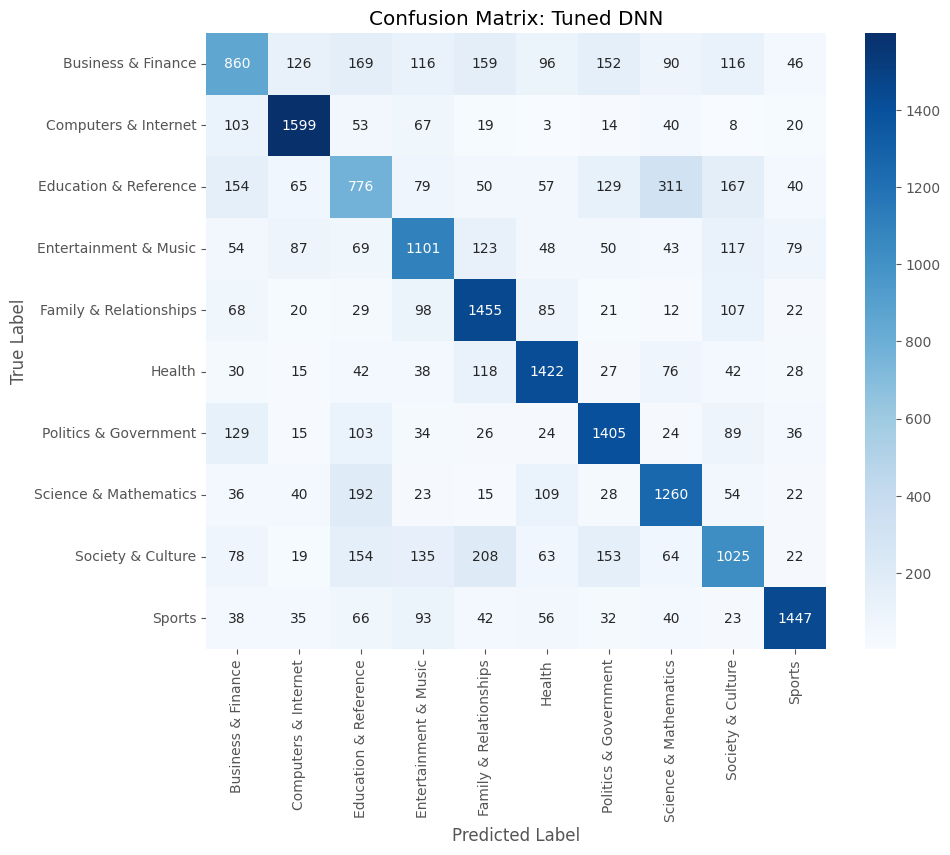

In [38]:
from sklearn.metrics import classification_report
import numpy as np

def print_report(model, X_data, y_true, model_name="Model"):
    # 1. Predict (returns probabilities for each of the 10 classes)
    y_pred_probs = model.predict(X_data)
    
    # 2. Convert Probabilities to Class Labels (Pick the highest probability)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)
    
    # 3. Get the Class Names (Optional: makes the report readable)
    # We use the LabelEncoder 'le' from Step 4
    class_names = [str(c) for c in le.classes_]
    
    print(f"\n--- Classification Report: {model_name} ---")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

# --- Example Usage for your Tuned DNN ---
# Make sure to use the correct X data (TF-IDF for DNN, Padded for GRU)
print_report(model_dnn_tuned, X_val_tfidf, y_val, "DNN Run 2 (Tuned)")


import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

def plot_confusion_matrix(model, X_data, y_true, title="Confusion Matrix"):
    # 1. Predict
    y_pred_probs = model.predict(X_data)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)
    
    # 2. Compute Matrix
    cm = confusion_matrix(y_true, y_pred_classes)
    
    # 3. Plot Heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=le.classes_, 
                yticklabels=le.classes_)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(title)
    plt.show()

# Run it for your Tuned DNN
plot_confusion_matrix(model_dnn_tuned, X_val_tfidf, y_val, "Confusion Matrix: Tuned DNN")

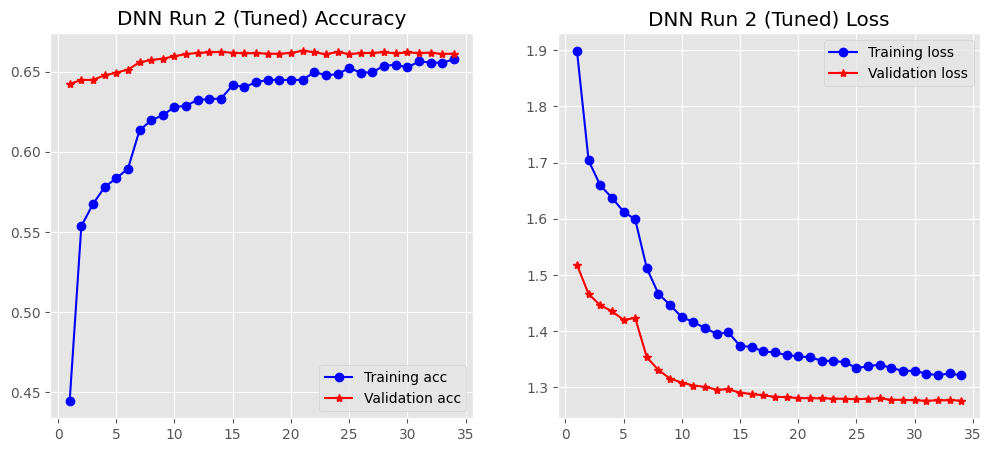

In [36]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training acc')
    plt.plot(epochs, val_acc, 'r*-', label='Validation acc')
    plt.title(f'{model_name} Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation loss')
    plt.title(f'{model_name} Loss')
    plt.legend()

    plt.show()

# Plot the Tuned DNN results
plot_history(history_dnn_tuned, "DNN Run 2 (Tuned)")

Skip-Gram

In [42]:
import gensim
from gensim.models import Word2Vec
import numpy as np

sentences = [text.split() for text in X_train]


w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4, sg=1)

print(f"Word2Vec Trained. Vocab size: {len(w2v_model.wv)}")

embedding_matrix = np.zeros((VOCAB_SIZE, 100))

for word, i in tokenizer.word_index.items():
    if i < VOCAB_SIZE:
        if word in w2v_model.wv:
            embedding_matrix[i] = w2v_model.wv[word]

print(f"Embedding Matrix Shape: {embedding_matrix.shape}")

Word2Vec Trained. Vocab size: 110862
Embedding Matrix Shape: (20000, 100)


GRU

In [45]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout

# 1. Build Model
model_gru_sg = Sequential([
    # THE KEY CHANGE: Loading pre-trained Skip-gram weights
    Embedding(input_dim=VOCAB_SIZE, 
              output_dim=100, 
              weights=[embedding_matrix], 
              input_length=MAX_LENGTH, 
              trainable=False), # False = Keep the Skip-gram weights fixed
    
    # Basic GRU
    GRU(128, return_sequences=False),
    
    # Dropout
    Dropout(0.5),
    
    # Output
    Dense(10, activation='softmax')
])

model_gru_sg.compile(loss='sparse_categorical_crossentropy', 
                     optimizer='adam', 
                     metrics=['accuracy'])

print("--- GRU (Basic) with Skip-gram Embeddings ---")
model_gru_sg.summary()

# 2. Train (Safe Batch Size)
history_gru_sg = model_gru_sg.fit(
    X_train_padded, y_train,
    epochs=10,
    batch_size=32, # Keeping it safe for your RAM
    validation_data=(X_val_padded, y_val),
    verbose=1
)

--- GRU (Basic) with Skip-gram Embeddings ---
Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     (None, 200, 100)          2000000   
                                                                 
 gru_1 (GRU)                 (None, 128)               88320     
                                                                 
 dropout_13 (Dropout)        (None, 128)               0         
                                                                 
 dense_19 (Dense)            (None, 10)                1290      
                                                                 
Total params: 2,089,610
Trainable params: 89,610
Non-trainable params: 2,000,000
_________________________________________________________________
Epoch 1/10
2334/2334 [==============================] - 55s 23ms/step - loss: 2.2625 - accuracy: 0.1247 - val_loss: 1.5950 - 

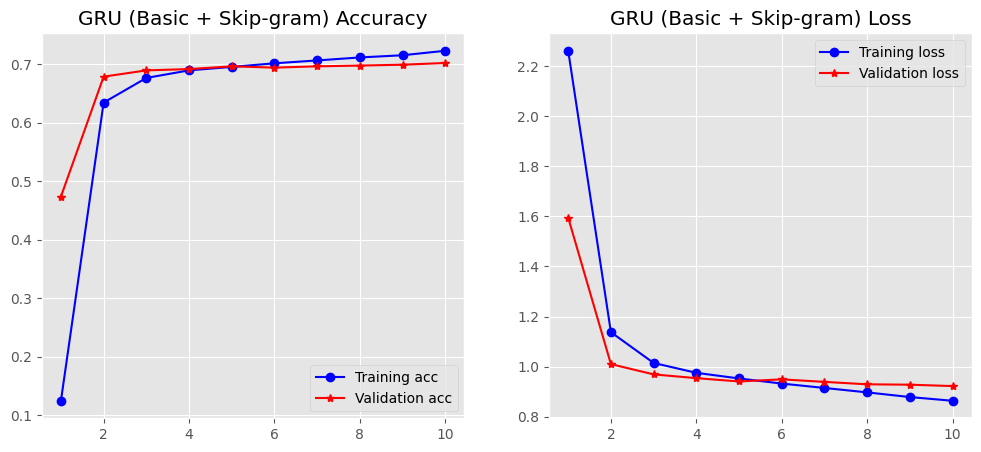

584/584 [==============================] - 6s 9ms/step

--- Classification Report: GRU (Basic + Skip-gram) ---
                        precision    recall  f1-score   support

    Business & Finance       0.62      0.46      0.53      1930
  Computers & Internet       0.83      0.86      0.85      1926
 Education & Reference       0.52      0.52      0.52      1828
 Entertainment & Music       0.65      0.71      0.68      1771
Family & Relationships       0.68      0.79      0.74      1917
                Health       0.73      0.83      0.78      1838
 Politics & Government       0.73      0.78      0.75      1885
 Science & Mathematics       0.69      0.72      0.71      1779
     Society & Culture       0.63      0.56      0.59      1921
                Sports       0.90      0.80      0.85      1872

              accuracy                           0.70     18667
             macro avg       0.70      0.70      0.70     18667
          weighted avg       0.70      0.70      0.70  

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import numpy as np

# --- A. Plot History ---
def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training acc')
    plt.plot(epochs, val_acc, 'r*-', label='Validation acc')
    plt.title(f'{model_name} Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation loss')
    plt.title(f'{model_name} Loss')
    plt.legend()

    plt.show()

plot_history(history_gru_sg, "GRU (Basic + Skip-gram)")


# --- B. Classification Report ---
def print_report(model, X_data, y_true, model_name="Model"):
    # 1. Predict
    y_pred_probs = model.predict(X_data)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)
    
    # 2. Get Class Names
    class_names = [str(c) for c in le.classes_]
    
    # 3. Print
    print(f"\n--- Classification Report: {model_name} ---")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

# Run report using the Padded Validation Data
print_report(model_gru_sg, X_val_padded, y_val, "GRU (Basic + Skip-gram)")

GRU-Tuned

In [47]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Define Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=1, min_lr=0.0001)

model_gru_tuned = Sequential([
    Embedding(input_dim=VOCAB_SIZE, 
              output_dim=100, 
              weights=[embedding_matrix], 
              input_length=MAX_LENGTH, 
              trainable=True), 
    
    # Add a second GRU layer for more "depth" (Stacking GRUs)
    GRU(64, return_sequences=True), 
    Dropout(0.5),
    
    GRU(32, return_sequences=False), # Second GRU layer
    Dropout(0.5),
    
    Dense(10, activation='softmax')
])

model_gru_tuned.compile(loss='sparse_categorical_crossentropy', 
                        optimizer='adam', 
                        metrics=['accuracy'])

model_gru_tuned.summary()

# 3. Train
history_gru_tuned = model_gru_tuned.fit(
    X_train_padded, y_train,
    epochs=15,
    batch_size=16,
    validation_data=(X_val_padded, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_2 (Embedding)     (None, 200, 100)          2000000   
                                                                 
 gru_2 (GRU)                 (None, 200, 64)           31872     
                                                                 
 dropout_14 (Dropout)        (None, 200, 64)           0         
                                                                 
 gru_3 (GRU)                 (None, 32)                9408      
                                                                 
 dropout_15 (Dropout)        (None, 32)                0         
                                                                 
 dense_20 (Dense)            (None, 10)                330       
                                                                 
Total params: 2,041,610
Trainable params: 2,041,610
No

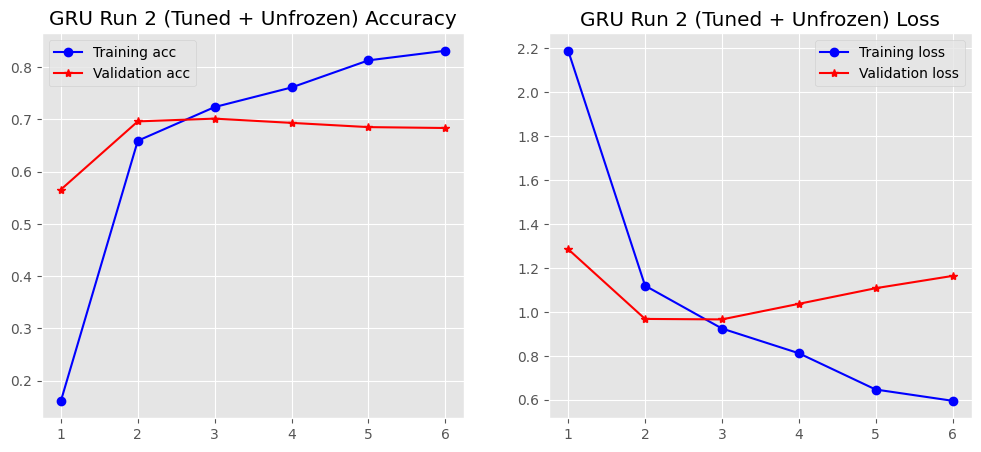


--- Classification Report: GRU Run 2 (Tuned) ---
584/584 [==============================] - 9s 15ms/step
                        precision    recall  f1-score   support

    Business & Finance       0.66      0.45      0.54      1930
  Computers & Internet       0.80      0.88      0.84      1926
 Education & Reference       0.55      0.48      0.51      1828
 Entertainment & Music       0.73      0.66      0.69      1771
Family & Relationships       0.68      0.77      0.72      1917
                Health       0.74      0.79      0.76      1838
 Politics & Government       0.75      0.76      0.75      1885
 Science & Mathematics       0.65      0.76      0.70      1779
     Society & Culture       0.57      0.62      0.59      1921
                Sports       0.87      0.84      0.86      1872

              accuracy                           0.70     18667
             macro avg       0.70      0.70      0.70     18667
          weighted avg       0.70      0.70      0.70     18

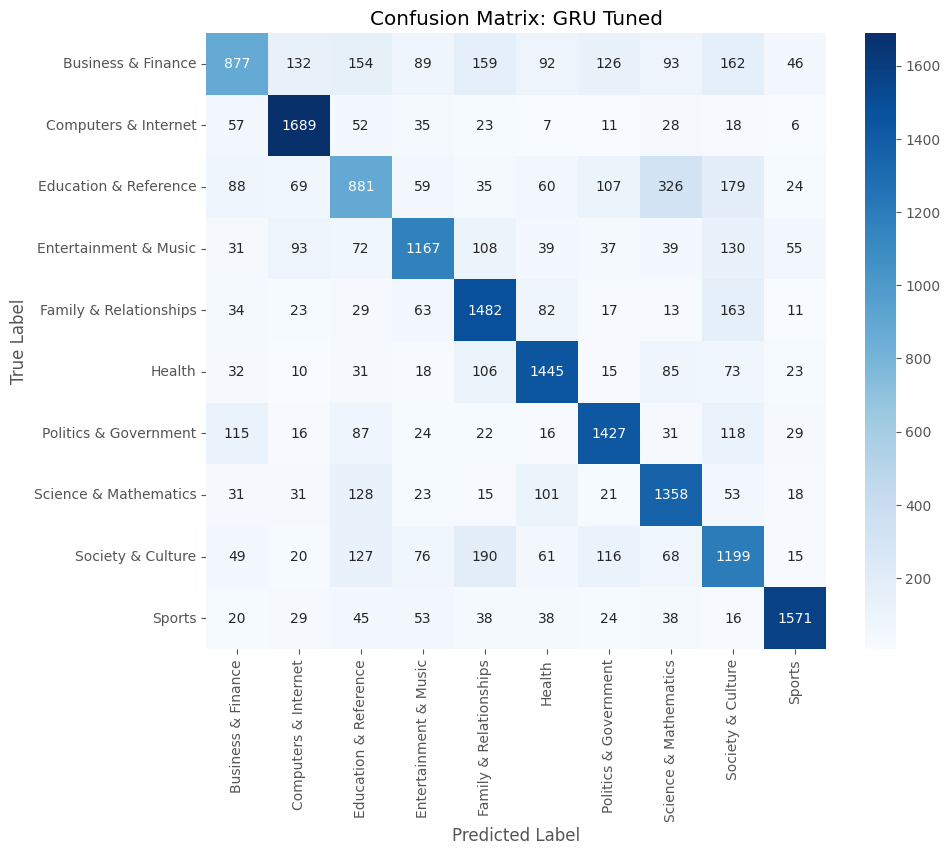

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# --- 1. Plot Training History (Accuracy & Loss) ---
def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    
    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training acc')
    plt.plot(epochs, val_acc, 'r*-', label='Validation acc')
    plt.title(f'{model_name} Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation loss')
    plt.title(f'{model_name} Loss')
    plt.legend()

    plt.show()

# Plot the graph using the history from the step you just ran
plot_history(history_gru_tuned, "GRU Run 2 (Tuned + Unfrozen)")


# --- 2. Classification Report ---
# (Shows Precision, Recall, and F1-Score for every category)
def print_report(model, X_data, y_true, model_name="Model"):
    print(f"\n--- Classification Report: {model_name} ---")
    
    # Predict
    y_pred_probs = model.predict(X_data)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)
    
    # Get names
    class_names = [str(c) for c in le.classes_]
    
    # Print
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

print_report(model_gru_tuned, X_val_padded, y_val, "GRU Run 2 (Tuned)")


# --- 3. Confusion Matrix Heatmap ---
# (Shows exactly which topics are getting confused)
def plot_confusion_matrix(model, X_data, y_true, title="Confusion Matrix"):
    # Predict
    y_pred_probs = model.predict(X_data)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)
    
    # Compute Matrix
    cm = confusion_matrix(y_true, y_pred_classes)
    
    # Plot
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=le.classes_, 
                yticklabels=le.classes_)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(title)
    plt.show()

plot_confusion_matrix(model_gru_tuned, X_val_padded, y_val, "Confusion Matrix: GRU Tuned")

Bidirectional_GRU

In [50]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Define Callbacks (Smart Training)
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=1, min_lr=0.0001)

# 2. Build the Model
model_bigru = Sequential([
    # EMBEDDING LAYER: Loads your Skip-gram weights
    # trainable=True allows the model to "fine-tune" the Skip-gram vectors
    Embedding(input_dim=VOCAB_SIZE, 
              output_dim=100, 
              weights=[embedding_matrix], 
              input_length=MAX_LENGTH, 
              trainable=True), 
    
    # Reads text Forwards AND Backwards
    Bidirectional(GRU(64, return_sequences=True)),
    Dropout(0.5),
    
    # BIDIRECTIONAL GRU (Layer 2)
    # Stacking layers helps catch deeper patterns
    Bidirectional(GRU(32)), 
    Dropout(0.5),
    
    # Output Layer
    Dense(10, activation='softmax')
])

model_bigru.compile(loss='sparse_categorical_crossentropy', 
                    optimizer='adam', 
                    metrics=['accuracy'])

print("--- Bidirectional GRU + Skip-gram (Tuned) ---")
model_bigru.summary()

# 3. Train
history_bigru = model_bigru.fit(
    X_train_padded, y_train,
    epochs=10,
    batch_size=32, # Safe mode for RAM
    validation_data=(X_val_padded, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

--- Bidirectional GRU + Skip-gram (Tuned) ---
Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_4 (Embedding)     (None, 200, 100)          2000000   
                                                                 
 bidirectional_2 (Bidirectio  (None, 200, 128)         63744     
 nal)                                                            
                                                                 
 dropout_18 (Dropout)        (None, 200, 128)          0         
                                                                 
 bidirectional_3 (Bidirectio  (None, 64)               31104     
 nal)                                                            
                                                                 
 dropout_19 (Dropout)        (None, 64)                0         
                                                                 
 dense_

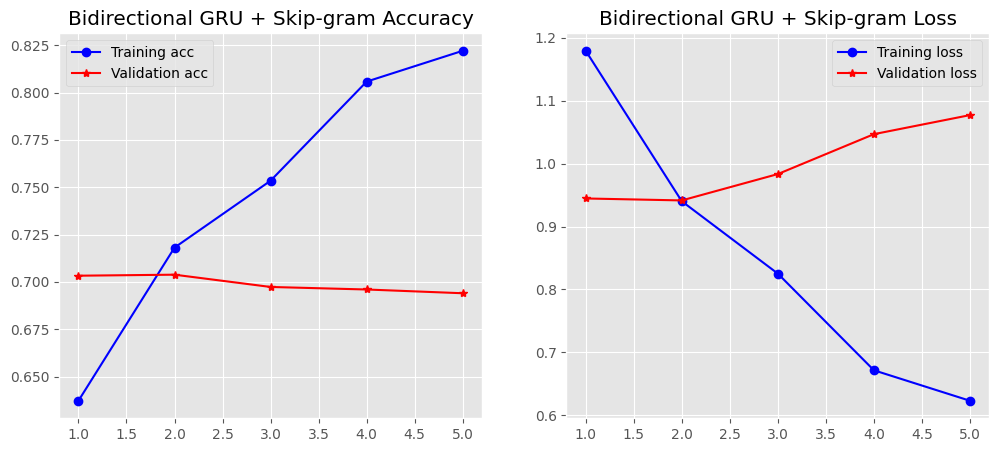


--- Classification Report: Bi-GRU + Skip-gram ---
584/584 [==============================] - 19s 31ms/step
                        precision    recall  f1-score   support

    Business & Finance       0.61      0.47      0.53      1930
  Computers & Internet       0.86      0.83      0.85      1926
 Education & Reference       0.51      0.51      0.51      1828
 Entertainment & Music       0.73      0.68      0.70      1771
Family & Relationships       0.73      0.75      0.74      1917
                Health       0.76      0.79      0.77      1838
 Politics & Government       0.70      0.81      0.75      1885
 Science & Mathematics       0.68      0.73      0.70      1779
     Society & Culture       0.59      0.63      0.61      1921
                Sports       0.88      0.85      0.86      1872

              accuracy                           0.70     18667
             macro avg       0.70      0.70      0.70     18667
          weighted avg       0.70      0.70      0.70     

In [51]:
# Reuse your plotting functions
plot_history(history_bigru, "Bidirectional GRU + Skip-gram")

print_report(model_bigru, X_val_padded, y_val, "Bi-GRU + Skip-gram")


Bidirectiona_GRU-TUNED

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout, Bidirectional, SpatialDropout1D, GlobalMaxPooling1D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Define Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=0.0001)

# 2. Build Optimized Model
model_bigru_opt = Sequential([
    # Embedding: Skip-gram weights, Trainable
    Embedding(input_dim=VOCAB_SIZE, 
              output_dim=100, 
              weights=[embedding_matrix], 
              input_length=MAX_LENGTH, 
              trainable=True),
    
    # OPTIMIZATION 1: SpatialDropout1D
    # Drops entire 1D feature maps instead of individual elements
    SpatialDropout1D(0.3),
    
    # Layer 1: Bi-GRU with L2 Regularization
    Bidirectional(GRU(64, return_sequences=True, kernel_regularizer=l2(0.0001))),
    
    # Layer 2: Bi-GRU (Must return sequences for GlobalMaxPooling)
    Bidirectional(GRU(32, return_sequences=True, kernel_regularizer=l2(0.0001))),
    
    # OPTIMIZATION 2: GlobalMaxPooling1D
    # Extracts the most important features from the entire sentence sequence
    GlobalMaxPooling1D(),
    
    # Dense Layer for feature interpretation
    Dense(32, activation='relu', kernel_regularizer=l2(0.0001)),
    Dropout(0.5),
    
    # Output
    Dense(10, activation='softmax')
])

model_bigru_opt.compile(loss='sparse_categorical_crossentropy', 
                        optimizer='adam', 
                        metrics=['accuracy'])

print("--- Optimized Bidirectional GRU (SpatialDropout + MaxPooling) ---")
model_bigru_opt.summary()

# 3. Train
history_bigru_opt = model_bigru_opt.fit(
    X_train_padded, y_train,
    epochs=20,          # Increased epochs (EarlyStopping will save us)
    batch_size=16,      # Keeping safe batch size
    validation_data=(X_val_padded, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

--- Optimized Bidirectional GRU (SpatialDropout + MaxPooling) ---
Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_5 (Embedding)     (None, 200, 100)          2000000   
                                                                 
 spatial_dropout1d (SpatialD  (None, 200, 100)         0         
 ropout1D)                                                       
                                                                 
 bidirectional_4 (Bidirectio  (None, 200, 128)         63744     
 nal)                                                            
                                                                 
 bidirectional_5 (Bidirectio  (None, 200, 64)          31104     
 nal)                                                            
                                                                 
 global_max_pooling1d (Globa  (None, 64)             

In [ ]:
# Plot History
plot_history(history_bigru_opt, "Optimized Bi-GRU")

# Print Report
print_report(model_bigru_opt, X_val_padded, y_val, "Optimized Bi-GRU")

# Confusion Matrix
plot_confusion_matrix(model_bigru_opt, X_val_padded, y_val, "Confusion Matrix: Optimized Bi-GRU")